# Visualization — Lecture Activity

**Physics 305 (HPC)** · Chapter 12, *High Performance Computing* (2018)

Name: _(fill in)_ · Date: _(fill in)_

Kernel: **Python (physics_305_hpc_env)**. Written answers go in the cells marked ✏️. Part D is the only part that needs code; it calls `viz_mpi.py` (next to this notebook) through `mpirun`.

## Learning outcomes

After completing this activity, students should be able to:

1. Distinguish parallel data processing from parallel rendering.
2. Trace a dataset through a distributed visualization pipeline.
3. Explain data partitioning and image compositing.
4. Interpret basic performance measurements and identify possible bottlenecks.

## Background (from the handout)

**How does an HPC system turn scientific data into an image?** Three stages: *read* the data, apply *filters* to extract useful information, and *render* an image. ParaView uses VTK algorithms for these and supports parallel execution for large datasets. In this activity, *parallel processing* means parallel **data** processing, and *parallel rendering* means parallel **image** generation.

**Parallel processing — working on the data.** Data-analysis or transformation tasks are distributed among MPI processes (*ranks*). The dataset is divided into partitions and each rank works on its own portion (isosurface extraction, gradients, thresholding). With four ranks extracting the surface $\rho(x,y,z)=\rho_0$, the result is *distributed geometry — not yet a picture*. Some operations need information from neighbouring partitions; *ghost cells* (copies of neighbouring cells) supply it near partition boundaries.

**Parallel rendering — producing the image.** In ParaView's *sort-last* approach each rank renders its portion of the geometry with a common camera, and the partial images are combined by *image compositing* (IceT library). Ranks do not necessarily render separate rectangular screen sections: geometry from different ranks can overlap in the image, so compositing must combine the contributions correctly.

```
Scientific dataset
      ↓
Partition among MPI ranks
      ↓
Parallel processing      — each rank extracts contour geometry
      ↓
Parallel rendering       — each rank renders its geometry
      ↓
Image compositing
      ↓
Final displayed image
```

**Why distinguish the two?** Processing produces data or geometry; rendering produces pixels. They can have different bottlenecks. Parallel processing does not always require parallel rendering: a small extracted surface can be sent to the client and rendered locally, while large geometry stays distributed and is rendered remotely (ParaView's *remote-rendering threshold* controls the choice).

**Performance measures.** Speedup $S_p = T_1/T_p$ and efficiency $E_p = S_p/p$, where $T_1$ is the one-rank time and $T_p$ the time on $p$ ranks. Always state whether a timing covers processing, rendering, or the complete workflow.

## Assigned reading

[ParaView Reference Manual: Remote and Parallel Visualization](https://docs.paraview.org/en/latest/ReferenceManual/parallelDataVisualization.html), focusing on:

- "Understanding parallel processing"
- "Ghost levels"
- "ParaView architecture"
- "Basic Parallel Rendering"
- "Parallel Render Parameters"

Reading notes (optional):

> ✏️ _(notes)_

---
## Part A. Check your understanding

Answer each question in two or three sentences.

**A1.** What is the main difference between parallel data processing and parallel rendering? Identify the output of each stage.

> ✏️ **Your answer:**
>
> Parallel data processing extracts geometries from scientific datasets. Parallel rendering handles visualization from geometries, converting them to various components of an image.

**A2.** In an MPI-based visualization workflow, what is a rank? Why is dividing the dataset among ranks useful?

> ✏️ **Your answer:**
>
> A rank is the direct analogue of a worker in a parallelized job, but for rendering. Each rank is assigned a partition of the dataset and produces geometries that can either be rendered on the cluster or locally. This makes visualization of large 
datasets using distributed computing on a cluster possible.

**A3.** Why might a rank need information from a neighboring partition? Explain the role of ghost cells.

> ✏️ **Your answer:**
>
> There are algorithms that rely on the boundaries of a cell, or on the data from another cell, say the external faces algorithm, or perhaps to calculate a gradient. Ghost cells represent a copy of the cells from another partition that are adjacent to the cells in the current partition, for these algorithms to be calculated, that can then absorb edge errors and be discarded later.

**A4.** What is image compositing, and why is it needed in ParaView's distributed rendering?

> ✏️ **Your answer:**
>
> Image compositing combines the distributed rendered geometries into a single image. The way that the dataset is distributed across ranks does not necessarily translate into independent sections of an image, but rather into geometries that can overlap from a given perspective, and so image compositing is required to translate the rendered geometries into a single image correctly.

**A5.** Can data be processed in parallel but rendered locally on one workstation? Describe a situation in which this arrangement would be appropriate.

> ✏️ **Your answer:**
>
> This works for a sufficiently small dataset such that the contour geometries and the rendering they require fit comfortably within the resources of said workstation.

---
## Part B. Classify the operations

Classify each operation: **P** = data processing, **R** = rendering, **C** = image compositing.
Assume that the data-processing and rendering operations are distributed across multiple ranks.

| # | Operation | Classification |
|---|---|:---:|
| 1 | Each rank calculates a temperature gradient in its assigned data partition. | ✏️ |
| 2 | Each rank generates a partial image of its assigned geometry. | ✏️ |
| 3 | The system merges partial images into one final image. | ✏️ |
| 4 | Each rank extracts the surface where electron density equals a selected value. | ✏️ |
| 5 | Each rank selects cells whose temperature exceeds a threshold. | ✏️ |
| 6 | Each rank generates an updated image after the user changes the camera position. | ✏️ |

---
## Part C. Trace a visualization workflow

A researcher has a large three-dimensional temperature dataset stored on an HPC system and wants to visualize the surface where

$$T(x, y, z) = 500$$

The dataset is distributed among four MPI ranks.

**C1.** Draw a labeled workflow showing data partitioning, contour extraction, rendering, image compositing, and final display. Identify where parallel processing and parallel rendering occur.

The cell below draws the skeleton. Edit `stage_notes` (and any labels) to complete it — or replace the cell with a photo of a hand-drawn diagram.

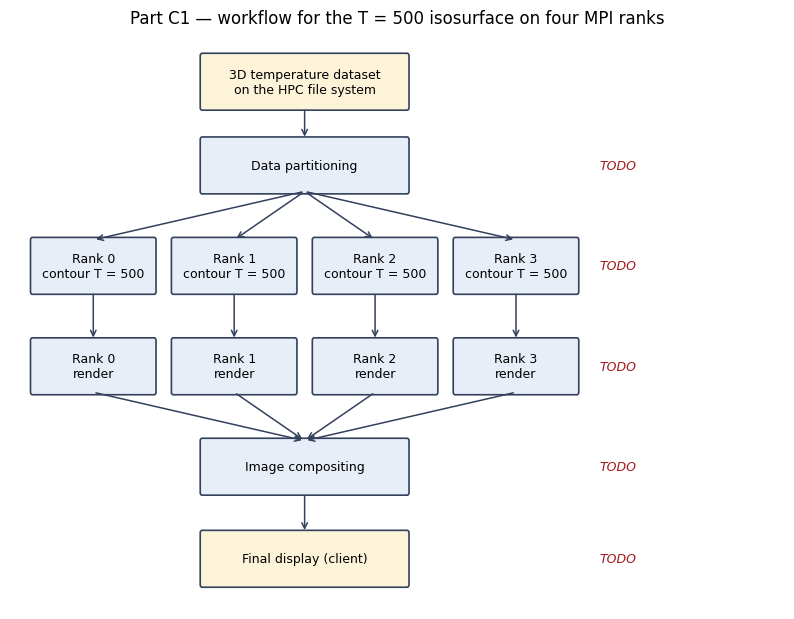

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

N_RANKS = 4

# ✏️ Fill these in: which kind of parallelism (if any) happens at each stage?
stage_notes = {
    "partition": "TODO",
    "contour":   "TODO",
    "render":    "TODO",
    "composite": "TODO",
    "display":   "TODO",
}

def box(ax, x, y, text, w=1.9, h=0.62, fc="#e8eef7"):
    ax.add_patch(FancyBboxPatch((x - w/2, y - h/2), w, h, boxstyle="round,pad=0.03",
                                fc=fc, ec="#33415c", lw=1.2))
    ax.text(x, y, text, ha="center", va="center", fontsize=9)

def arrow(ax, x0, y0, x1, y1):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="->", color="#33415c", lw=1.1))

fig, ax = plt.subplots(figsize=(10, 7.5))
xs = [2.2 * (i - (N_RANKS - 1) / 2) for i in range(N_RANKS)]
Y = dict(data=6, partition=5, contour=3.8, render=2.6, composite=1.4, display=0.3)

box(ax, 0, Y["data"], "3D temperature dataset\non the HPC file system", w=3.2, fc="#fdf3d8")
box(ax, 0, Y["partition"], "Data partitioning", w=3.2)
arrow(ax, 0, Y["data"] - .31, 0, Y["partition"] + .31)
for i, x in enumerate(xs):
    box(ax, x, Y["contour"], f"Rank {i}\ncontour T = 500")
    box(ax, x, Y["render"], f"Rank {i}\nrender")
    arrow(ax, 0, Y["partition"] - .31, x, Y["contour"] + .31)
    arrow(ax, x, Y["contour"] - .31, x, Y["render"] + .31)
    arrow(ax, x, Y["render"] - .31, 0, Y["composite"] + .31)
box(ax, 0, Y["composite"], "Image compositing", w=3.2)
box(ax, 0, Y["display"], "Final display (client)", w=3.2, fc="#fdf3d8")
arrow(ax, 0, Y["composite"] - .31, 0, Y["display"] + .31)

for key, note in stage_notes.items():
    ax.text(xs[-1] + 1.3, Y[key], note, ha="left", va="center", fontsize=9,
            color="#a4161a" if note == "TODO" else "#1b4332", style="italic")

ax.set_xlim(xs[0] - 1.3, xs[-1] + 4.2); ax.set_ylim(-0.3, 6.6); ax.axis("off")
ax.set_title("Part C1 — workflow for the T = 500 isosurface on four MPI ranks")
plt.show()

**C2.** Does contour extraction produce an image or geometry? Explain your answer.

> ✏️ **Your answer:**
>
> _(write here)_

**C3.** The extracted surface is much smaller than the original dataset. Describe an alternative workflow that uses parallel processing but local rendering. State what must be transferred to the client.

> ✏️ **Your answer:**
>
> _(write here)_

---
## Part D. Analyze performance

> Create a set of streamlines, isosurfaces, and volume renderings of the function
> $f(x,y,z) = 2550\,\sin(50x)\,\sin(50y)\,\cos(50z)$ using the visualization tool of your choice using HPC resources.
> Produce a strong scaling plot showing the time to solution for the visualization as a function of the number of computing resources employed.

### How this is set up

**Tool:** VTK driven from Python, with MPI through `mpi4py` — the same pipeline ParaView runs, written out explicitly in `viz_mpi.py` so each stage can be timed separately. (ParaView's conda build has no MPI, so `pvbatch` cannot run on several ranks in this environment.)

| Stage (timer name) | What each rank does | Kind |
|---|---|---|
| `generate` | fills its own z-slab of the $N^3$ grid (stands in for reading its piece) | — |
| `gradient` | $\nabla f$ by finite differences on the slab plus ghost layers | processing |
| `contour` | isosurfaces $f = \pm 1275$ (`vtkFlyingEdges3D`) | processing |
| `stream` | streamlines of $\nabla f$ from the seeds in its slab (`vtkStreamTracer`, RK45) | processing |
| `render_iso`, `render_stream` | draws its own triangles / lines, common camera | rendering |
| `render_volume` | ray-casts its own slab (`vtkFixedPointVolumeRayCastMapper`, one thread) | rendering |
| `composite` | partial images are sent to rank 0 and merged (depth test for geometry, back-to-front blending for the volume) | compositing |

Things to keep in mind when interpreting the numbers:

- **Strong scaling:** the problem ($N$, image size, seeds) is fixed while the rank count $p$ grows.
- Streamlines need a vector field; as in the chapter's VTK example it is the gradient of the scalar field. The domain is the unit cube $[0,1]^3$ (the handout does not specify one) — change it with `--length`.
- Every rank is limited to one thread, so speedup comes from MPI ranks only.
- Each stage time is the **slowest rank's** time for that stage; `pipeline` is the sum of all stages.
- Ghost layers: a gradient line of $f$ never leaves its nodal cell (edge $\pi/50$), so $\lceil \pi/50h\rceil + 2$ ghost layers let every rank trace its streamlines without talking to its neighbours. The cost is extra points per rank (reported below).
- `render_iso` / `render_stream` use OpenGL. On a laptop all ranks share **one GPU**; on a cluster each node would use its own GPU or a software rasterizer.

In [2]:
import json, os, shutil, subprocess, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

HERE = Path.cwd()
SCRIPT = HERE / "viz_mpi.py"
RESULTS = HERE / "results"
RESULTS.mkdir(exist_ok=True)

# mpi4py in this env is built against Homebrew's Open MPI, so use its mpirun.
MPIRUN = shutil.which("mpirun") or "/opt/homebrew/bin/mpirun"

N = 256                     # grid points per axis (N^3 points in total)
IMAGE_SIZE = 800            # pixels per side
RANKS = [p for p in (1, 2, 4, 8) if p <= os.cpu_count()]
REPEATS = 3                 # timing repeats per rank count (the fastest is kept)

assert SCRIPT.exists(), "viz_mpi.py must be in the same folder as this notebook"
print("mpirun :", MPIRUN)
print("python :", sys.executable)
print("cores  :", os.cpu_count(), "| rank counts:", RANKS)


def run_viz(p, out, n=N, images=True):
    # Run the pipeline on p MPI ranks and return its timing record.
    cmd = [MPIRUN, "-n", str(p), sys.executable, str(SCRIPT), "--n", str(n),
           "--size", str(IMAGE_SIZE), "--out", str(out)]
    if not images:
        cmd.append("--no-images")
    r = subprocess.run(cmd, capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr[-2000:])
    return json.loads((Path(out) / "timing.json").read_text())

mpirun : /opt/homebrew/bin/mpirun
python : /opt/homebrew/Caskroom/miniforge/base/envs/physics_305_hpc_env/bin/python
cores  : 8 | rank counts: [1, 2, 4, 8]


### D1. The function

A quick look at a slice before any 3D work. $f$ is a lattice of alternating maxima and minima, separated by nodal planes every $\pi/50 \approx 0.063$.

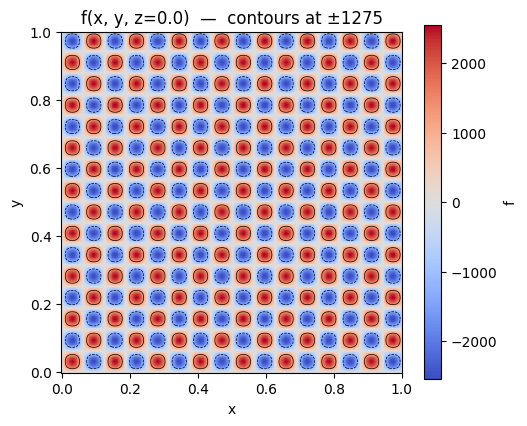

In [3]:
x = np.linspace(0, 1, 400)
X, Y = np.meshgrid(x, x)
z0 = 0.0
F = 2550 * np.sin(50 * X) * np.sin(50 * Y) * np.cos(50 * z0)

fig, ax = plt.subplots(figsize=(5.5, 4.6))
im = ax.pcolormesh(X, Y, F, cmap="coolwarm", shading="auto", vmin=-2550, vmax=2550)
ax.contour(X, Y, F, levels=[-1275, 1275], colors="k", linewidths=0.5)
ax.set(xlabel="x", ylabel="y", title=f"f(x, y, z={z0})  —  contours at ±1275", aspect="equal")
fig.colorbar(im, label="f")
plt.show()

### D2. The three visualizations

One run on several ranks; the images shown are the *composited* results.

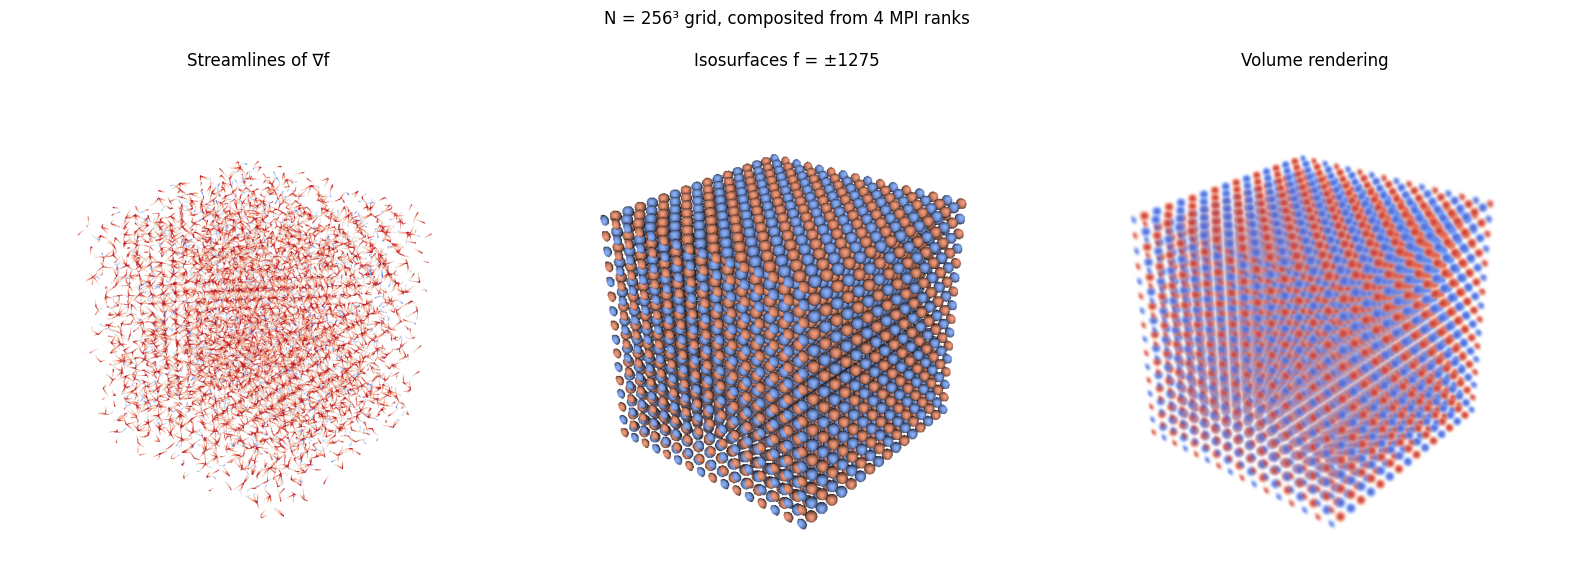

triangles: 4,665,572   streamlines: 7,979   ghost layers per side: 19


In [4]:
P_SHOW = RANKS[-1] if len(RANKS) < 3 else 4
rec = run_viz(P_SHOW, RESULTS / f"images_p{P_SHOW}")

titles = {"stream": "Streamlines of ∇f", "iso": "Isosurfaces f = ±1275", "volume": "Volume rendering"}
fig, axes = plt.subplots(1, 3, figsize=(16, 5.6))
for ax, (name, title) in zip(axes, titles.items()):
    ax.imshow(mpimg.imread(RESULTS / f"images_p{P_SHOW}" / f"{name}.png"))
    ax.set_title(title); ax.axis("off")
fig.suptitle(f"N = {rec['n']}³ grid, composited from {rec['ranks']} MPI ranks", y=1.03)
plt.tight_layout(); plt.show()

print(f"triangles: {rec['triangles']:,}   streamlines: {rec['streamlines']:,}   "
      f"ghost layers per side: {rec['ghost_layers']}")

### D3. Does the answer depend on the number of ranks?

Before timing anything, check that partitioning does not change the result: same geometry counts, and (nearly) the same pixels, on 1 rank and on several.

In [5]:
ref = run_viz(1, RESULTS / "images_p1")

print(f"{'':12s}{'1 rank':>14s}{str(P_SHOW) + ' ranks':>14s}")
for key in ("triangles", "streamlines", "streamline_points"):
    print(f"{key:12.12s}{ref[key]:>14,}{rec[key]:>14,}")

print("\npixel differences (colour channels scaled 0–1):")
for name in ("iso", "stream", "volume"):
    a = mpimg.imread(RESULTS / "images_p1" / f"{name}.png")[..., :3]
    b = mpimg.imread(RESULTS / f"images_p{P_SHOW}" / f"{name}.png")[..., :3]
    d = np.abs(a - b)
    print(f"  {name:7s} max {d.max():.3f}   mean {d.mean():.5f}   "
          f"pixels differing by > 0.05: {100 * (d.max(-1) > 0.05).mean():.2f}%")

                    1 rank       4 ranks
triangles        4,665,572     4,665,572
streamlines          7,979         7,979
streamline_p       190,526       190,526

pixel differences (colour channels scaled 0–1):
  iso     max 0.004   mean 0.00000   pixels differing by > 0.05: 0.00%
  stream  max 0.000   mean 0.00000   pixels differing by > 0.05: 0.00%
  volume  max 0.114   mean 0.00213   pixels differing by > 0.05: 0.14%


### D4. Strong-scaling measurements

Fixed problem, increasing ranks. Each configuration is run `REPEATS` times and the fastest time per stage is kept. Results are cached in `results/scaling.json`; set `RERUN = True` to measure again.

In [6]:
RERUN = False
cache = RESULTS / "scaling.json"

if cache.exists() and not RERUN:
    runs = json.loads(cache.read_text())
    print("loaded cached measurements from", cache.name)
else:
    runs = []
    for p in RANKS:
        for rep in range(REPEATS):
            r = run_viz(p, RESULTS / "tmp", images=False)
            r["repeat"] = rep
            runs.append(r)
            print(f"p = {p}  repeat {rep}: pipeline {r['times']['pipeline']:.3f} s")
    cache.write_text(json.dumps(runs, indent=1))

STAGES = ["generate", "gradient", "contour", "stream",
          "render_iso", "render_stream", "render_volume", "composite"]
GROUPS = ["processing", "render", "composite", "pipeline"]

ps = sorted({r["ranks"] for r in runs})
T = {k: np.array([min(r["times"][k] for r in runs if r["ranks"] == p) for p in ps])
     for k in STAGES + GROUPS}
ghost_overhead = [next(r for r in runs if r["ranks"] == p) for p in ps]
ghost_overhead = [r["points_with_ghosts"] / r["points_owned"] for r in ghost_overhead]

print(f"\nN = {runs[0]['n']}³, image {runs[0]['image_size']}², times in seconds\n")
print(f"{'stage':15s}" + "".join(f"{'p=' + str(p):>9s}" for p in ps))
for k in STAGES + GROUPS:
    if k == "processing":
        print("-" * (15 + 9 * len(ps)))
    print(f"{k:15s}" + "".join(f"{t:9.3f}" for t in T[k]))
print(f"{'ghost overhead':15s}" + "".join(f"{g:8.2f}x" for g in ghost_overhead))

print("\nspeedup S_p = T_1/T_p and efficiency E_p = S_p/p\n")
print(f"{'':15s}" + "".join(f"{'p=' + str(p):>14s}" for p in ps))
for k in GROUPS:
    S = T[k][0] / T[k]
    print(f"{k:15s}" + "".join(f"{s:7.2f} ({100 * s / p:3.0f}%)" for s, p in zip(S, ps)))

loaded cached measurements from scaling.json

N = 256³, image 800², times in seconds

stage                p=1      p=2      p=4      p=8
generate           0.029    0.018    0.013    0.023
gradient           0.104    0.068    0.059    0.070
contour            0.350    0.175    0.104    0.081
stream             0.467    0.292    0.212    0.267
render_iso         1.161    0.717    0.520    0.573
render_stream      0.135    0.099    0.085    0.113
render_volume      0.544    0.408    0.301    0.287
composite          0.019    0.046    0.085    0.216
---------------------------------------------------
processing         0.929    0.535    0.376    0.428
render             1.851    1.225    0.906    0.973
composite          0.019    0.046    0.085    0.216
pipeline           2.832    1.826    1.391    1.673
ghost overhead     1.00x    1.15x    1.44x    2.01x

speedup S_p = T_1/T_p and efficiency E_p = S_p/p

                          p=1           p=2           p=4           p=8
processing 

### D5. Strong-scaling plot

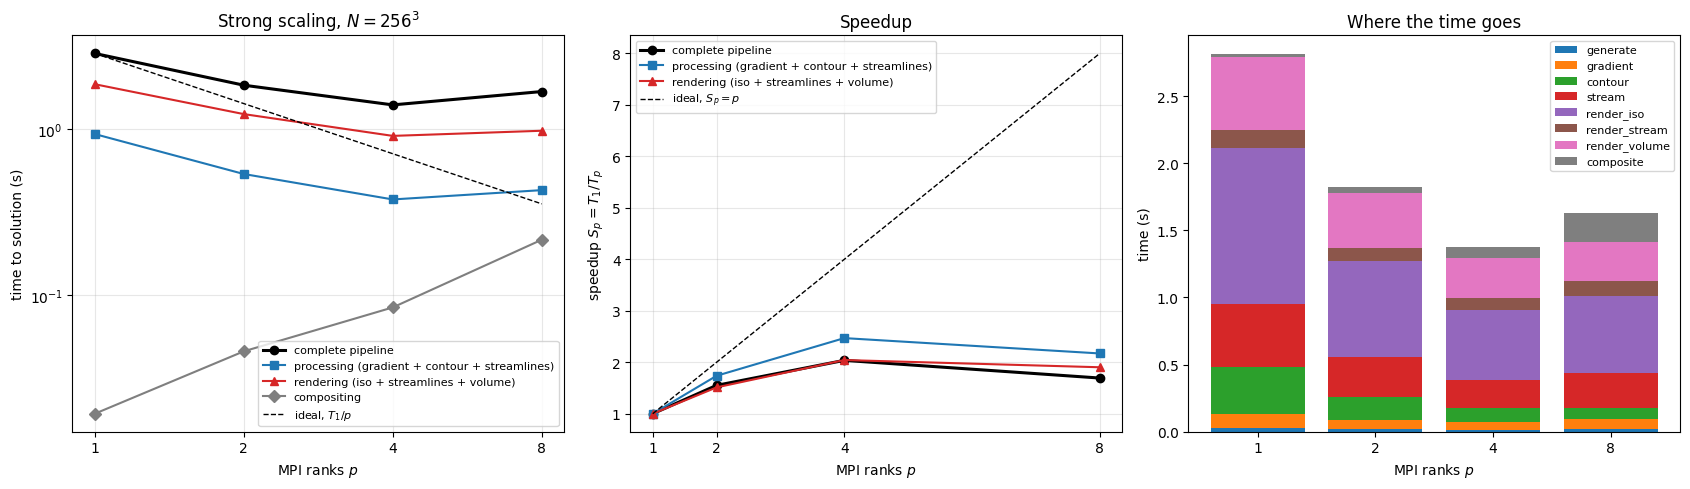

In [7]:
pa = np.array(ps)
style = {"pipeline":   dict(color="black",   marker="o", lw=2.2, label="complete pipeline"),
         "processing": dict(color="#1f77b4", marker="s", lw=1.5, label="processing (gradient + contour + streamlines)"),
         "render":     dict(color="#d62728", marker="^", lw=1.5, label="rendering (iso + streamlines + volume)"),
         "composite":  dict(color="#7f7f7f", marker="D", lw=1.5, label="compositing")}

fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(17, 5))

for k, st in style.items():
    a1.plot(pa, T[k], **st)
a1.plot(pa, T["pipeline"][0] / pa, "k--", lw=1, label="ideal, $T_1/p$")
a1.set(xscale="log", yscale="log", xlabel="MPI ranks $p$", ylabel="time to solution (s)",
       title=f"Strong scaling, $N = {runs[0]['n']}^3$")
a1.set_xticks(pa); a1.set_xticklabels(pa); a1.minorticks_off()
a1.grid(alpha=.3, which="both"); a1.legend(fontsize=8)

for k in ("pipeline", "processing", "render"):
    a2.plot(pa, T[k][0] / T[k], **style[k])
a2.plot(pa, pa, "k--", lw=1, label="ideal, $S_p = p$")
a2.set(xlabel="MPI ranks $p$", ylabel="speedup $S_p = T_1/T_p$", title="Speedup")
a2.set_xticks(pa); a2.grid(alpha=.3); a2.legend(fontsize=8)

bottom = np.zeros(len(ps))
cmap = plt.get_cmap("tab10")
for i, k in enumerate(STAGES):
    a3.bar([str(p) for p in ps], T[k], bottom=bottom, label=k, color=cmap(i))
    bottom += T[k]
a3.set(xlabel="MPI ranks $p$", ylabel="time (s)", title="Where the time goes")
a3.legend(fontsize=8)

plt.tight_layout()
fig.savefig(RESULTS / "strong_scaling.png", dpi=160)
plt.show()

### D6. Interpretation

Points worth addressing (delete this list when done):

- Which stage dominates $T_1$, and which dominates at the largest $p$? Did the bottleneck move?
- Which stages scale well and which do not — and why? (Think: shared GPU, ghost-layer overhead, image transfer to rank 0, fixed per-rank setup cost, performance vs. efficiency cores on a laptop.)
- Does compositing time grow with $p$? What would IceT do differently from a plain gather on rank 0?
- State explicitly whether each number you quote is processing, rendering, or the complete workflow.

> ✏️ **Your answer:**
>
> _(write here)_

### Running on a cluster (optional)

`viz_mpi.py` is self-contained, so the same measurement runs under a batch scheduler; `run_scaling.slurm` is a template. Two things differ from the laptop: compute nodes usually have no display, so VTK must be an off-screen build (EGL or OSMesa — `pip install vtk-osmesa` or the site's ParaView/VTK module), and `mpi4py` should be built against the cluster's MPI (`module load` it first, then `pip install --no-binary mpi4py mpi4py`). Copy the resulting `results/` folder back and re-run cells D4–D5 on the cached file.

---
## Part E. Evaluate a claim

A student states:

> "If ParaView runs on eight MPI ranks, each rank must render exactly one-eighth of the screen, and the final visualization will always be eight times faster."

Write a 100–150-word response correcting the statement. Address:

- How geometry partitions differ from screen regions.
- Why compositing is necessary.
- Why increasing rank count does not guarantee proportional speedup.

Use at least one specific idea from the assigned reading.

Write the response in the string below; running the cell shows it formatted with a word count.

In [8]:
from IPython.display import Markdown, display

response = """
(write your 100–150-word response here)
"""

n_words = len(response.split())
ok = 100 <= n_words <= 150
display(Markdown(f"> {response.strip()}\n\n**{n_words} words** — "
                 + ("within 100–150 ✅" if ok else "target is 100–150 ⚠️")))

> (write your 100–150-word response here)

**5 words** — target is 100–150 ⚠️

---
## References

1. <https://docs.paraview.org/en/v6.2.0/Tutorials/SelfDirectedTutorial/introduction.html>
2. <https://docs.paraview.org/en/latest/ReferenceManual/parallelDataVisualization.html>
3. <https://docs.paraview.org/en/latest/UsersGuide/displayingData.html>
4. <https://docs.paraview.org/en/v6.0.1/references.html>
5. <https://docs.paraview.org/en/v5.10.1/UsersGuide/introduction.html>
6. <https://docs.paraview.org/en/v5.13.1/Tutorials/SelfDirectedTutorial/>
7. <https://docs.paraview.org/en/latest/ReferenceManual/index.html>
8. <https://docs.paraview.org/en/latest/Tutorials/SelfDirectedTutorial/furtherReading.html>
9. <https://docs.paraview.org/en/latest/ReferenceManual/advancedRendering.html>
10. <https://docs.paraview.org/en/v5.13.2/Tutorials/SelfDirectedTutorial/visualizingLargeModels.html>

## AI use disclosure

This notebook was created with the assistance of Claude (Fable 5.2). The prompt included an
instruction to replicate the activity PDF and set up a template for student input and for 
the initial code to generate flowcharts, visualizations, and the data processing
pipelines. AI was not used to produce answers to questions requiring word-based responses.